# SpearMace policy: proof of concept

A candidate-scoring policy trained to imitate the gym's expert (beam 8x5). One shared MLP scores
each candidate action, and a softmax over the decision's candidates gives the policy.
Data building lives in [`policy_data.py`](policy_data.py) and the model in [`policy_model.py`](policy_model.py).

> **Proof of concept, not a deployable policy.**
> - It is trained on the two runs recorded *before* the stale-`onGround` fix (decisions right after a
>   pearl catch saw `onGround=true` in mid-air). The data is used as is; section 5 reports that subset separately.
> - Only offline imitation is measured here (does it pick what the expert picks?). Whether that wins
>   fights needs a gym evaluation, which is out of scope.

**Two feature sets**

| set | features | decisions |
|---|---|---|
| `full` | state + action parameters + the simulator's predicted outcome of each candidate | only decisions where *every* candidate was simulated |
| `no_outcome` | state + action parameters | all labelled decisions |

The Rules agent stops simulating at the first candidate that works, so its own pick is always the one
with an outcome. Using outcome features on those decisions would leak the acting agent's choice,
which is why `full` leaves them out. That makes `full` mostly Beam/MCTS decisions.

**Targets.** `alpha · softmax(expert_best / T) + (1 − alpha) · onehot(expert pick)`. `expert_best` is the best rank
anywhere below a candidate, but the beam picks the top of its deepest level, so the two disagree on about
11% of decisions. Candidates the expert found infeasible (no value) get no probability.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import torch

import spearmace_data as sd
import policy_data as pdm
import policy_model as pm

torch.set_num_threads(8)
pd.set_option("display.width", 200)

SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
mpl.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "lines.linewidth": 2,
    "axes.prop_cycle": mpl.cycler(color=SLOTS), "legend.frameon": False,
})

## 1. Data

In [2]:
RUNS = [sd.GYM_DIR / "20261105-002113", sd.GYM_DIR / "20261105-075355"]  # pre-fix runs
raw = sd.load_runs(RUNS, with_candidates=True)
data = {fs: pdm.build(RUNS, fs, data=raw) for fs in pdm.FEATURE_SETS}

rows = []
for fs, d in data.items():
    for split in pdm.SPLITS:
        idx = d.split(split)
        rows.append({"feature set": fs, "split": split, "decisions": len(idx),
                     "side-episodes": d.meta.episode_key.iloc[idx].nunique(),
                     "mean candidates": d.mask[idx].sum(1).mean().round(2)})
display(pd.DataFrame(rows).pivot(index="split", columns="feature set"))
print("features:", {fs: len(d.feature_names) for fs, d in data.items()})

decisions            side-episodes            mean candidates           
feature set      full no_outcome          full no_outcome            full no_outcome
split                                                                               
test             8385      20564           207        218            4.84       4.87
train           51358     130810          1603       1680            5.08       5.01
val              5625      16002           177        190            5.07       4.99

features: {'full': 82, 'no_outcome': 58}


In [3]:
# sanity checks
for fs, d in data.items():
    assert d.meta.groupby("episode_key").split.nunique().max() == 1, "episode crosses splits"
    assert not any(n.startswith(("acted", "expert")) for n in d.feature_names), "leaky feature"
    assert d.mask[np.arange(len(d.label)), d.label].all(), "label outside candidates"
print("splits are disjoint by side-episode; no acted_/expert_ features; labels inside candidate sets")
data["full"].meta.search.value_counts().to_frame("full decisions by acting search")

splits are disjoint by side-episode; no acted_/expert_ features; labels inside candidate sets


,full decisions by acting search
search,
Beam search,35369
MCTS,25604
Rules,4355


## 2. Choosing the target temperature and mix (validation set, `full`)

In [4]:
grid = []
for T in (1.0, 3.0, 10.0):
    for alpha in (0.0, 0.5, 1.0):
        if alpha == 0.0 and T != 1.0:
            continue  # T doesn't matter for hard labels
        r = pm.train(data["full"], pm.TrainConfig(temperature=T, alpha=alpha), verbose=False)
        h = r.history[r.best_epoch]
        grid.append({"T": T, "alpha": alpha, "best epoch": r.best_epoch,
                     "val loss": h["val_loss"], "val top-1": h["val_top1"]})
grid = pd.DataFrame(grid).sort_values("val top-1", ascending=False)
grid.round(4)

,T,alpha,best epoch,val loss,val top-1
0,1.0,0.0,53,0.7026,0.7198
1,1.0,0.5,56,0.7621,0.7100
3,3.0,0.5,56,0.7833,0.7095
5,10.0,0.5,56,0.8367,0.7090
4,3.0,1.0,53,0.8160,0.6725
2,1.0,1.0,56,0.7803,0.6720
6,10.0,1.0,59,0.9022,0.6546


In [5]:
best = grid.iloc[0]
# the grid ranks configs at 60 epochs; the final models may train longer (early stopping decides)
CFG = pm.TrainConfig(temperature=float(best["T"]), alpha=float(best["alpha"]), max_epochs=200, patience=10)
print("chosen:", CFG)

results = {fs: pm.train(d, CFG, verbose=False) for fs, d in data.items()}
for fs, r in results.items():
    print(f"{fs}: best epoch {r.best_epoch}, saved to", pm.save(r, data[fs], f"poc_{fs}"))

chosen: TrainConfig(temperature=1.0, alpha=0.0, hidden=128, dropout=0.1, lr=0.001, weight_decay=0.0001, batch_size=1024, max_epochs=200, patience=10, seed=0)


full: best epoch 75, saved to /home/jimin/Documents/Github/Wurst7-SpearMace/analysis/models/poc_full.pt
no_outcome: best epoch 122, saved to /home/jimin/Documents/Github/Wurst7-SpearMace/analysis/models/poc_no_outcome.pt


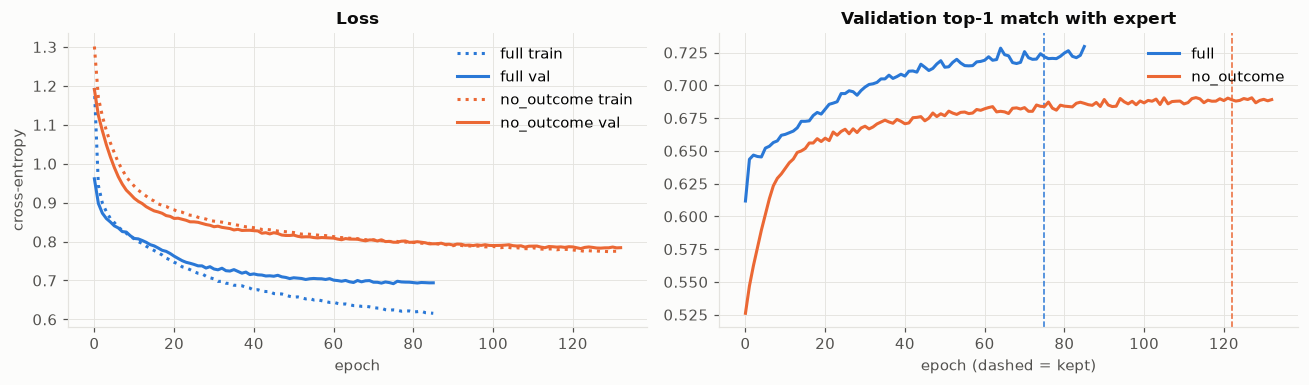

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for (fs, r), c in zip(results.items(), SLOTS):
    h = pd.DataFrame(r.history)
    axes[0].plot(h.epoch, h.train_loss, color=c, linestyle=":", label=f"{fs} train")
    axes[0].plot(h.epoch, h.val_loss, color=c, label=f"{fs} val")
    axes[1].plot(h.epoch, h.val_top1, color=c, label=fs)
    axes[1].axvline(r.best_epoch, color=c, linewidth=1, linestyle="--")
axes[0].set(title="Loss", xlabel="epoch", ylabel="cross-entropy")
axes[1].set(title="Validation top-1 match with expert", xlabel="epoch (dashed = kept)")
axes[0].legend(); axes[1].legend()
plt.tight_layout()

## 3. Test-set results vs baselines

In [7]:
def bootstrap_ci(hit, groups, n=1000, seed=0):
    """95% CI of the mean, resampling side-episodes."""
    df = pd.DataFrame({"hit": hit, "g": groups.to_numpy()})
    per = df.groupby("g").hit.agg(["sum", "size"])
    rng = np.random.default_rng(seed)
    s, k = per["sum"].to_numpy(), per["size"].to_numpy()
    draws = rng.integers(0, len(per), (n, len(per)))
    means = s[draws].sum(1) / k[draws].sum(1)
    return np.percentile(means, [2.5, 97.5])

def type_prior(d):
    """P(expert picks type | type offered), from the train split."""
    tr = d.split("train")
    cols = [d.feature_names.index(f"c_type_{t}") for t in pdm.TYPES]
    offered = d.X[tr][:, :, cols].sum((0, 1))
    picked = d.X[tr, d.label[tr]][:, cols].sum(0)
    return picked / np.maximum(offered, 1), cols

def report(fs):
    d, r = data[fs], results[fs]
    te = d.split("test"); m = d.meta.iloc[te]
    p = pm.predict(r.model, d, te)
    label = d.label[te]
    top1 = p.argmax(1) == label
    top3 = (np.argsort(-p, 1)[:, :3] == label[:, None]).any(1)
    prior, cols = type_prior(d)
    prior_score = np.where(d.mask[te], (d.X[te][:, :, cols] * prior).sum(-1), -1)
    not_explored = ~m.explored.to_numpy()
    rows = {
        "model top-1": top1, "model top-3": top3,
        "random (1/n)": 1 / d.mask[te].sum(1),
        "type prior": prior_score.argmax(1) == label,
        "greedy dealt−taken": m.greedy_idx.to_numpy() == label,
        "acting agent (not explored)": np.where(not_explored, m.acted_idx.to_numpy() == label, np.nan),
    }
    out = []
    for k, v in rows.items():
        ok = ~np.isnan(v.astype(float))
        lo, hi = bootstrap_ci(v[ok].astype(float), m.episode_key[ok])
        out.append({"": k, "match": v[ok].mean(), "95% CI low": lo, "95% CI high": hi})
    return pd.DataFrame(out).set_index(""), p, top1

reports = {fs: report(fs) for fs in data}
for fs, (tbl, _, _) in reports.items():
    print(f"== {fs} ({len(data[fs].split('test')):,} test decisions)")
    display(tbl.round(3))

== full (8,385 test decisions)


,match,95% CI low,95% CI high
,,,
model top-1,0.728,0.715,0.742
model top-3,0.972,0.967,0.977
random (1/n),0.264,0.254,0.274
type prior,0.478,0.461,0.498
greedy dealt−taken,0.308,0.273,0.337
acting agent (not explored),0.648,0.594,0.703


== no_outcome (20,564 test decisions)


,match,95% CI low,95% CI high
,,,
model top-1,0.700,0.693,0.707
model top-3,0.964,0.960,0.966
random (1/n),0.249,0.243,0.255
type prior,0.416,0.406,0.424
greedy dealt−taken,0.343,0.327,0.354
acting agent (not explored),0.503,0.477,0.536


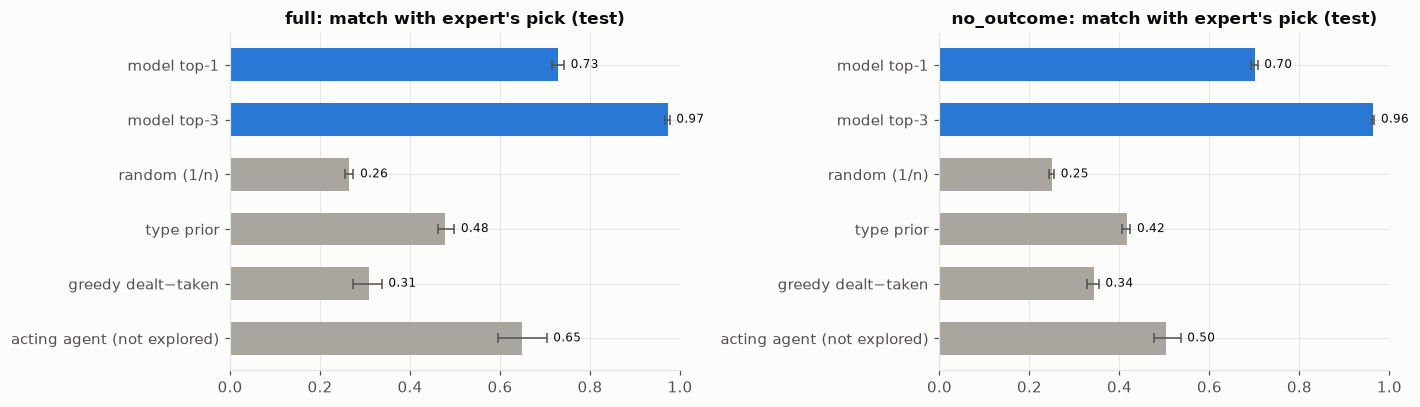

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)
for ax, (fs, (tbl, _, _)) in zip(axes, reports.items()):
    t = tbl.iloc[::-1]
    colors = [SLOTS[0] if k.startswith("model") else "#a8a69f" for k in t.index]
    ax.barh(t.index, t["match"], color=colors, height=0.6)
    ax.errorbar(t["match"], range(len(t)), xerr=[t["match"] - t["95% CI low"], t["95% CI high"] - t["match"]],
                fmt="none", ecolor=INK2, lw=1, capsize=3)
    for y, (v, hi) in enumerate(zip(t["match"], t["95% CI high"])):
        ax.text(hi + 0.015, y, f"{v:.2f}", va="center", fontsize=8, color=INK)
    ax.set(title=f"{fs}: match with expert's pick (test)", xlim=(0, 1))
plt.tight_layout()

Reference points from the EDA: the acting agents agree with the expert about 42% (Rules) and 66%
(Beam/MCTS) of the time, and beam configs close to the expert's agree about 87%. That is a rough
ceiling for imitation, because the expert's own pick depends on how far its search got.

## 4. Where the model gets it right or wrong

In [9]:
def breakdown(fs, by):
    d = data[fs]; te = d.split("test"); m = d.meta.iloc[te].copy()
    m["hit"] = reports[fs][2]
    return m.groupby(by).hit.agg(["mean", "size"]).rename(columns={"mean": "top-1", "size": "n"})

# note: the few Rules decisions in `full` are ones where every candidate was simulated, i.e. all
# but the last failed, so the feasible one is usually obvious
display(pd.concat({fs: breakdown(fs, "search") for fs in data}, axis=1).round(3))
pd.concat({fs: breakdown(fs, "label_type") for fs in data}, axis=1).round(3).sort_values(("full", "n"), ascending=False)

full       no_outcome       
             top-1     n      top-1      n
search                                    
Beam search  0.715  5397      0.707   5397
MCTS         0.699  2440      0.675   2468
Rules        0.978   548      0.703  12699

full       no_outcome      
                top-1     n      top-1     n
label_type                                  
Hold            0.710  2185      0.629  3874
SpearLunge      0.825  1753      0.812  5035
Drift           0.667  1338      0.729  3800
WindChargeJump  0.772   839      0.758  2799
EscapeLunge     0.784   676      0.740  1622
PearlCatch      0.652   560      0.540   848
Cushion         0.808   369      0.837   775
MaceStrike      0.740   369      0.368   807
Eat             0.341   290      0.381   995
Escape          0.000     6      0.444     9

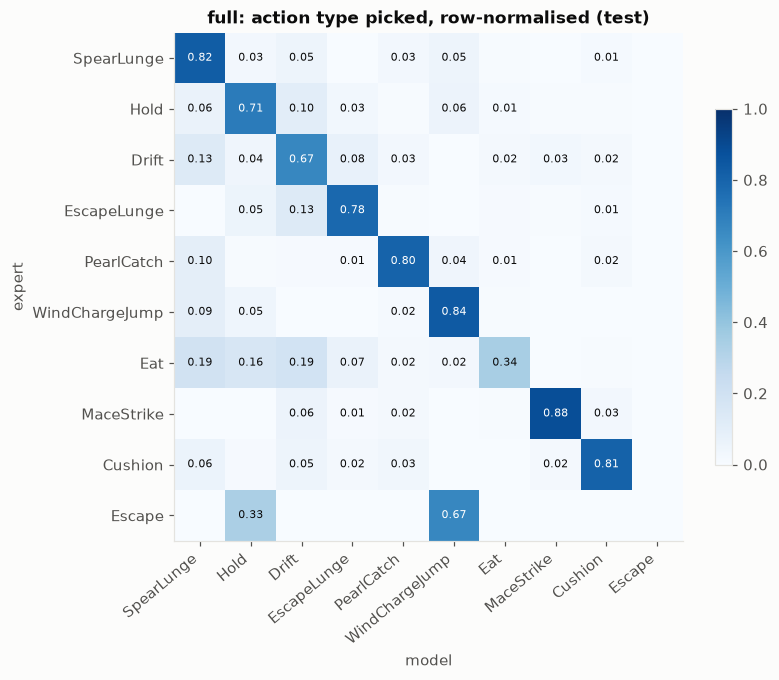

In [10]:
d = data["full"]; te = d.split("test"); p = reports["full"][1]
types = np.array(pdm.TYPES)
cols = [d.feature_names.index(f"c_type_{t}") for t in pdm.TYPES]
def type_of(idx_in_decision):
    return types[d.X[te, idx_in_decision][:, cols].argmax(1)]
pred_t, true_t = type_of(p.argmax(1)), type_of(d.label[te])
cm = pd.crosstab(pd.Series(true_t, name="expert"), pd.Series(pred_t, name="model"), normalize="index")
order = [t for t in pdm.TYPES if t in cm.index]
cm = cm.reindex(index=order, columns=order).fillna(0)

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(len(order)):
    for j in range(len(order)):
        v = cm.iat[i, j]
        if v >= 0.01:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.6 else INK)
ax.set_xticks(range(len(order)), order, rotation=40, ha="right")
ax.set_yticks(range(len(order)), order)
ax.set(title="full: action type picked, row-normalised (test)", xlabel="model", ylabel="expert")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7);

In [11]:
# accuracy vs number of candidates and vs how decisive the expert was
d = data["full"]; te = d.split("test")
v = np.where(d.mask[te] & ~np.isnan(d.values[te]), d.values[te], -np.inf)
top2 = -np.sort(-v, 1)[:, :2]
gap = np.where(np.isfinite(top2[:, 1]), top2[:, 0] - top2[:, 1], np.inf)
m = pd.DataFrame({"hit": reports["full"][2], "n": d.mask[te].sum(1),
                  "gap": pd.cut(gap, [-0.01, 0.1, 1, 5, 20, np.inf], labels=["<0.1", "0.1–1", "1–5", "5–20", ">20"])})
display(m.groupby("n").hit.agg(["mean", "size"]).T.round(3))
m.groupby("gap", observed=True).hit.agg(["mean", "size"]).rename(columns={"mean": "top-1"}).T.round(3)

n,2,3,4,5,6,7,8,9,10
mean,0.93,0.75,0.674,0.667,0.636,0.668,0.662,0.633,0.708
size,1425.00,1733.00,1734.000,436.000,291.000,1184.000,998.000,430.000,154.000


gap,<0.1,0.1–1,1–5,5–20,>20
top-1,0.576,0.675,0.594,0.673,0.85
size,974.000,1109.000,1092.000,1611.000,3599.00


## 5. The stale-`onGround` subset

These decisions were made while the logs said `onGround=true` but the player was more than 0.5 blocks
above the floor (the bug fixed in this change). The expert planned from the same wrong state, so its
labels there are consistent but describe a situation that no longer happens.

In [12]:
rows = []
for fs in data:
    d = data[fs]; te = d.split("test"); m = d.meta.iloc[te]
    hit = reports[fs][2]
    for flag, name in ((True, "stale onGround"), (False, "rest")):
        sel = m.stale_ground.to_numpy() == flag
        rows.append({"feature set": fs, "subset": name, "test decisions": int(sel.sum()),
                     "top-1": hit[sel].mean() if sel.any() else np.nan})
    rows.append({"feature set": fs, "subset": "share of all decisions (all splits)",
                 "test decisions": np.nan, "top-1": d.meta.stale_ground.mean()})
pd.DataFrame(rows).round(3)

,feature set,subset,test decisions,top-1
0,full,stale onGround,699.0,0.878
1,full,rest,7686.0,0.714
2,full,share of all decisions (all splits),NaN,0.093
3,no_outcome,stale onGround,968.0,0.845
4,no_outcome,rest,19596.0,0.693
5,no_outcome,share of all decisions (all splits),NaN,0.052


## 6. Which inputs matter (grouped permutation importance, `full`, test)

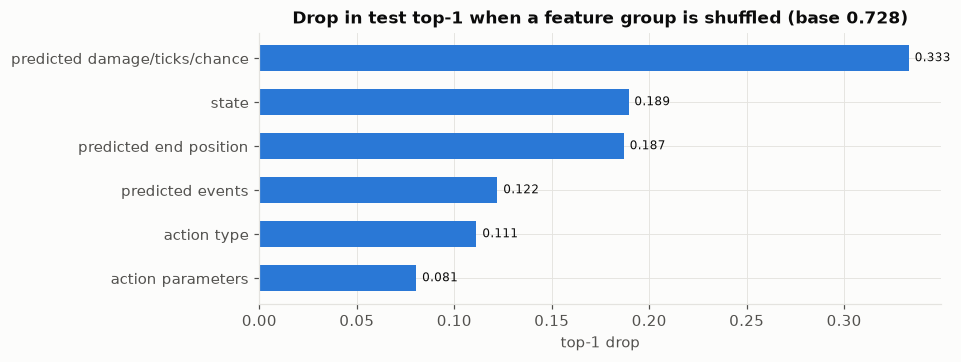

In [13]:
def group_of(name):
    if name.startswith("s_"): return "state"
    if name.startswith("c_type_"): return "action type"
    if name.startswith("c_"): return "action parameters"
    if name.startswith("o_ev_"): return "predicted events"
    if name.startswith("o_end"): return "predicted end position"
    return "predicted damage/ticks/chance"

d, r = data["full"], results["full"]
te = d.split("test")
base = (pm.predict(r.model, d, te).argmax(1) == d.label[te]).mean()
groups = pd.Series([group_of(n) for n in d.feature_names])
rng = np.random.default_rng(0)
imp = {}
X0 = d.X.copy()
for g in groups.unique():
    cols = np.flatnonzero(groups == g)
    Xp = X0[te].copy()
    perm = rng.permutation(len(te))
    if g == "state":
        Xp[:, :, cols] = Xp[perm][:, :, cols]          # swap whole decisions' state
    else:
        flat = Xp[:, :, cols].reshape(-1, len(cols))  # shuffle across candidates
        Xp[:, :, cols] = flat[rng.permutation(len(flat))].reshape(Xp.shape[0], Xp.shape[1], len(cols))
    d.X[te] = Xp
    imp[g] = base - (pm.predict(r.model, d, te).argmax(1) == d.label[te]).mean()
    d.X[te] = X0[te]
imp = pd.Series(imp).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(imp.index, imp.values, color=SLOTS[0], height=0.6)
for y, v in enumerate(imp.values):
    ax.text(v + 0.003, y, f"{v:.3f}", va="center", fontsize=8, color=INK)
ax.set(title=f"Drop in test top-1 when a feature group is shuffled (base {base:.3f})", xlabel="top-1 drop");

## 7. Takeaways

The cell below fills in the numbers. What to read from them:

- How far above the simple baselines (greedy, type prior) the model gets shows that the imitation signal is learnable from these features.
- How far the `full` model gets toward the acting Beam/MCTS agents' agreement (about 66%) and the near-expert ceiling (about 87%)
  shows how much headroom remains for a bigger model, more data, or better targets.
- Next steps outside this PoC: retrain on a post-fix gym run, simulate every candidate for every
  acting agent (or re-simulate offline) so `full` can use all decisions, and measure win rate in the gym.

In [14]:
summary = pd.DataFrame({fs: tbl["match"] for fs, (tbl, _, _) in reports.items()})
summary.round(3)

,full,no_outcome
,,
model top-1,0.728,0.700
model top-3,0.972,0.964
random (1/n),0.264,0.249
type prior,0.478,0.416
greedy dealt−taken,0.308,0.343
acting agent (not explored),0.648,0.503
